# 02 — EDA GameScope (360 filas: top + mid-tail)

Base: `data/processed/muestra_normalizada.csv` (200) + `muestra_midtail.csv` (160), observadas 2026-10-13. Sesgo conocido: top-popular, así que esto describe el techo del mercado, no el long-tail.

Preguntas: P1 géneros dominantes · P2 distribución de puntuaciones · P3 relación crítica-usuarios · P4 cobertura temporal · P5 cobertura de plataformas · P6 concentración de estudios. Cada una termina en conclusión escrita + decisión para la app.

In [1]:
import csv
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path("..")
rows = []
for fn in ("muestra_normalizada.csv", "muestra_midtail.csv"):
    rows += list(csv.DictReader((ROOT / "data" / "processed" / fn).open(encoding="utf-8")))

def num(v):
    try:
        return float(v) if v not in (None, "", "None") else None
    except ValueError:
        return None

print("Filas:", len(rows), "| RAWG:", sum(1 for r in rows if r["source"] == "rawg"),
      "| IGDB:", sum(1 for r in rows if r["source"] == "igdb"))

Filas: 360 | RAWG: 180 | IGDB: 180


## P1 ¿Qué géneros dominan por fuente?

Conclusión: ambas coronan un cajón amplio (RAWG `Action`, IGDB `Adventure`) seguido de Shooter/RPG/Indie. La regla de competidor necesita ≥2 géneros o ponderar rareza: con solo `Action` casi todo es candidato de todo.

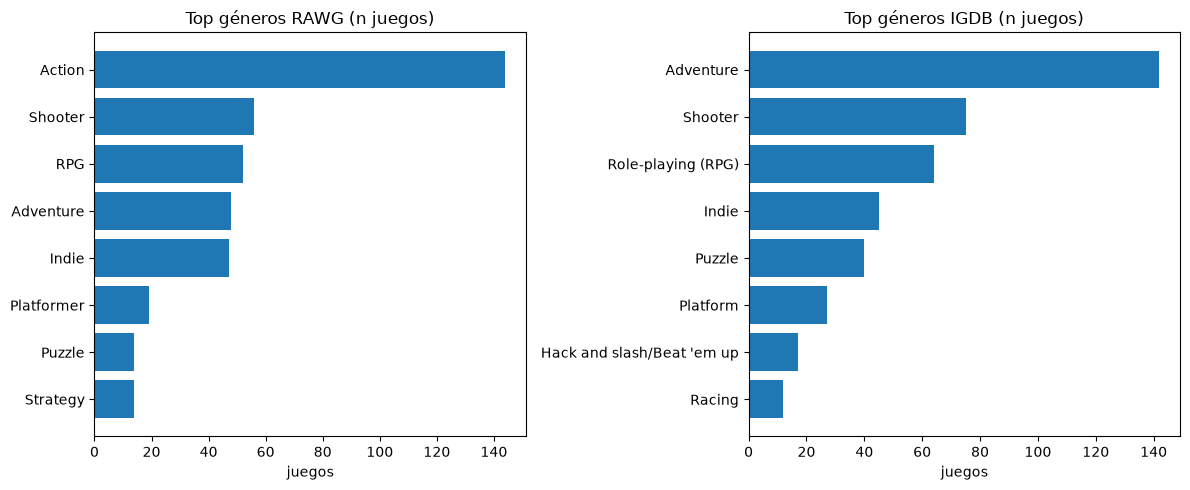

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=False)
for ax, src in zip(axes, ("rawg", "igdb")):
    c = Counter()
    for r in rows:
        if r["source"] == src:
            for x in (r["genre_names"] or "").split("|"):
                if x.strip():
                    c[x.strip()] += 1
    top = c.most_common(8)[::-1]
    ax.barh([k for k, _ in top], [v for _, v in top])
    ax.set_title(f"Top géneros {src.upper()} (n juegos)")
    ax.set_xlabel("juegos")
plt.tight_layout()
plt.show()

## P2 ¿Cómo se distribuyen las puntuaciones? (ojo: escalas distintas)

Medido: RAWG critic 0–100 (med 85) vs user 0–5 (med 4.11); IGDB critic (med 85.2) y user (med 85.0) ambas 0–100. Conclusión: medianas pegadas al techo por el sesgo top + escalas incompatibles entre fuentes → en la app, mostrar cada métrica con su escala y su n, nunca fusionar ni reescalar sin justificar.

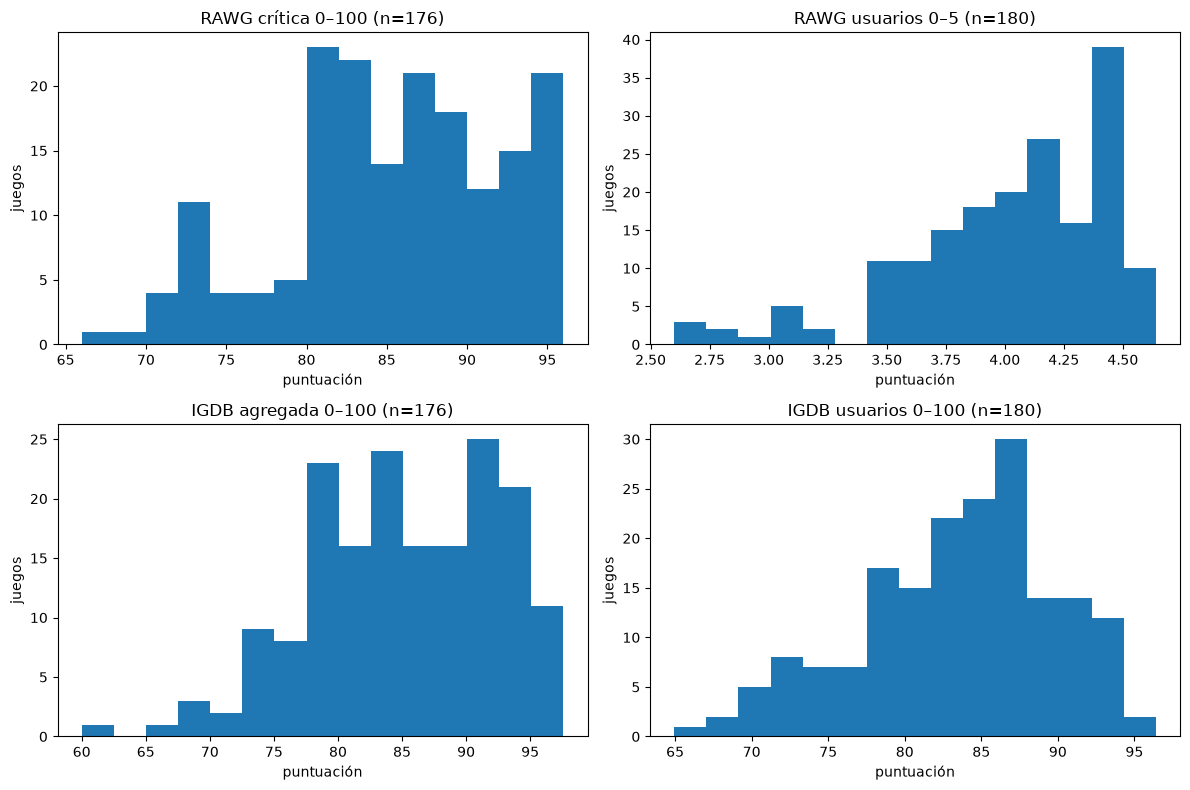

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
specs = [("rawg", "critic_score", "RAWG crítica 0–100"), ("rawg", "user_score", "RAWG usuarios 0–5"),
          ("igdb", "critic_score", "IGDB agregada 0–100"), ("igdb", "user_score", "IGDB usuarios 0–100")]
for ax, (src, col, title) in zip(axes.flat, specs):
    vs = [num(r[col]) for r in rows if r["source"] == src]
    vs = [x for x in vs if x is not None]
    ax.hist(vs, bins=15)
    ax.set_title(f"{title} (n={len(vs)})")
    ax.set_xlabel("puntuación"); ax.set_ylabel("juegos")
plt.tight_layout()
plt.show()

## P3 ¿Crítica y usuarios se mueven juntos?

Medido: Pearson ≈ 0.69 en ambas (n=176 pares). Conclusión: correlación moderada-alta pero con dispersión real + n muy distintos (prensa n≈11 vs usuarios n≈miles): sirven como dos señales complementarias lado a lado, y los conteos deben ponderar la confianza (un 90 con n=3 no vale lo mismo que con n=40).

rawg pearson: 0.689 n= 176
igdb pearson: 0.693 n= 176


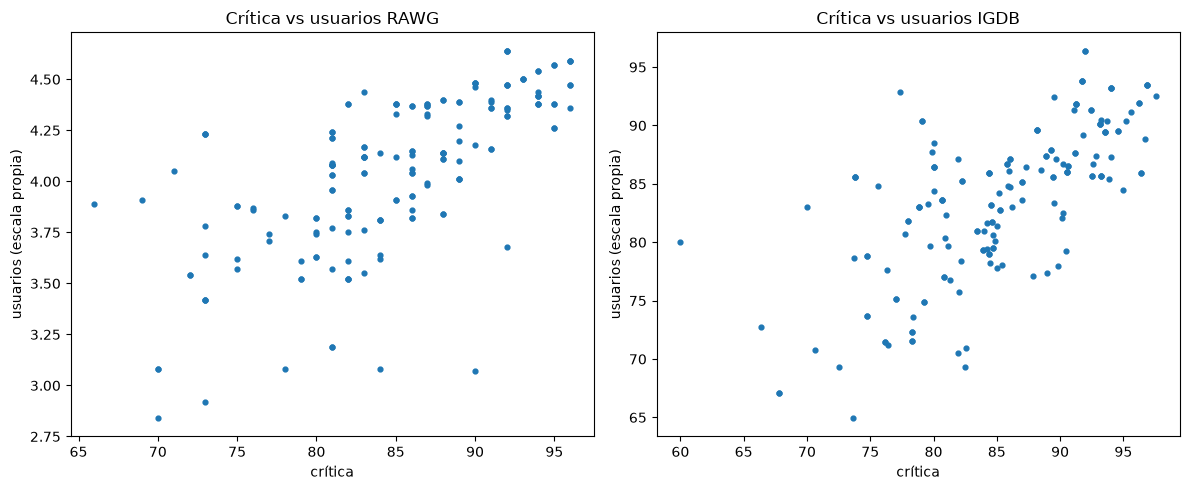

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, src in zip(axes, ("rawg", "igdb")):
    pairs = [(num(r["critic_score"]), num(r["user_score"])) for r in rows if r["source"] == src]
    pairs = [(a, b) for a, b in pairs if a is not None and b is not None]
    ax.scatter([a for a, _ in pairs], [b for _, b in pairs], s=12)
    ma = sum(a for a, _ in pairs) / len(pairs); mb = sum(b for _, b in pairs) / len(pairs)
    cov = sum((a - ma) * (b - mb) for a, b in pairs)
    va = sum((a - ma) ** 2 for a, _ in pairs); vb = sum((b - mb) ** 2 for _, b in pairs)
    print(src, "pearson:", round(cov / (va * vb) ** 0.5, 3), "n=", len(pairs))
    ax.set_title(f"Crítica vs usuarios {src.upper()}")
    ax.set_xlabel("crítica"); ax.set_ylabel("usuarios (escala propia)")
plt.tight_layout()
plt.show()

## P4 ¿Qué eras cubre la muestra?

Medido: mediana 2014 en ambas (RAWG 2002–2022, IGDB 1978–2025). Conclusión: ventana útil para comparar contemporáneos; la regla era ±4 queda calibrada alrededor de 2010–2018, y los clásicos (1978–2000) necesitan tratamiento aparte (remasters) en vez de forzarlos como competidores directos.

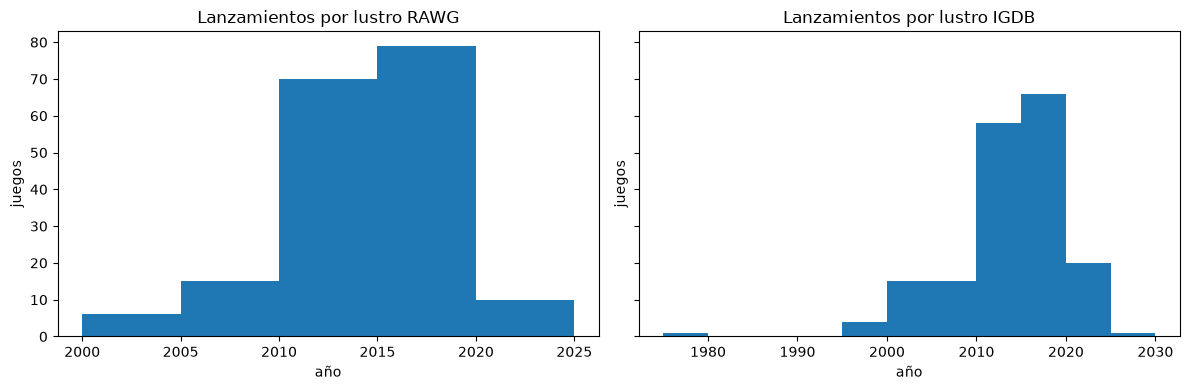

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, src in zip(axes, ("rawg", "igdb")):
    ys = [int(r["release_date"][:4]) for r in rows
          if r["source"] == src and (r["release_date"] or "")[:4].isdigit()]
    ax.hist(ys, bins=range(min(ys) // 5 * 5, max(ys) + 6, 5))
    ax.set_title(f"Lanzamientos por lustro {src.upper()}")
    ax.set_xlabel("año"); ax.set_ylabel("juegos")
plt.tight_layout()
plt.show()

## P5 ¿Cobertura real de plataformas por grupo?

Conclusión: casi todo el top es multiplataforma (PC presente en ~100/100 RAWG y 94/100 IGDB del top), así que el filtro por plataforma de la app es imprescindible: sin él, PC, Sony y Xbox muestran casi el mismo catálogo. Móvil (iOS/Android) es el único grupo con identidad propia parcial.

In [6]:
from collections import Counter
for src in ("rawg", "igdb"):
    c = Counter()
    for r in rows:
        if r["source"] == src:
            for x in (r["platform_names"] or "").split("|"):
                if x.strip():
                    c[x.strip()] += 1
    print(src, c.most_common(8))
    multi = sum(1 for r in rows if r["source"] == src and "|" in (r["platform_names"] or ""))
    n = sum(1 for r in rows if r["source"] == src)
    print(src, f"multiplataforma: {multi}/{n}")

rawg [('PC', 180), ('PlayStation 4', 146), ('Xbox One', 141), ('macOS', 96), ('Nintendo Switch', 85), ('Xbox 360', 72), ('Linux', 71), ('iOS', 65)]
rawg multiplataforma: 180/180
igdb [('PC (Microsoft Windows)', 166), ('PlayStation 4', 130), ('Xbox One', 109), ('Mac', 87), ('Nintendo Switch', 77), ('PlayStation 3', 73), ('Xbox 360', 69), ('iOS', 63)]
igdb multiplataforma: 176/180


## P6 ¿Concentración de estudios?

Medido (IGDB): Valve 11, Rockstar North 9, Ubisoft Montreal 8, FromSoftware 8. Conclusión: el top lo firman pocos estudios repetidos → el comparador debe evitar que “del mismo estudio” pese más que género+plataforma+era, o todos los candidatos de un piloto serán secuelas del mismo sello. RAWG-lista no permite este análisis (dev/pub solo en detalle).

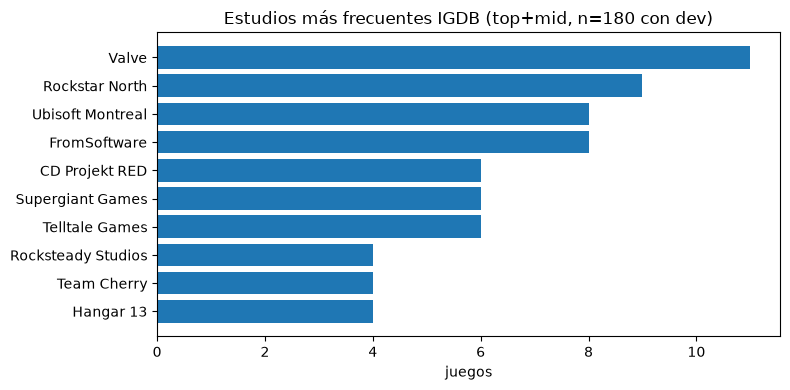

In [7]:
c = Counter()
for r in rows:
    if r["source"] == "igdb":
        for x in (r["developer_names"] or "").split("|"):
            if x.strip():
                c[x.strip()] += 1
top = c.most_common(10)[::-1]
plt.figure(figsize=(8, 4))
plt.barh([k for k, _ in top], [v for _, v in top])
plt.title("Estudios más frecuentes IGDB (top+mid, n=180 con dev)")
plt.xlabel("juegos")
plt.tight_layout()
plt.show()

## Decisiones para modelo y app (salen de este EDA)

1. Métricas siempre con escala + n visibles y sin fusionar (P2, P3).
2. Regla v1 endurecida: exigir ≥2 géneros equivalentes o ponderar rareza (P1).
3. Ponderar crítica por su n (mediana n≈11, máx 39): desconfiar de agregados con n<5 (P3).
4. Filtro por plataforma obligatorio; móvil como grupo diferenciado (P5).
5. Ventana era ±4 válida 2010–2018; clásicos aparte (P4).
6. Penalizar mismo-estudio en el score (P6). Siguiente: KPIs + primer snapshot versionado.